# 01 – Keşifsel Veri Analizi (EDA)

**Veri:** ChainCC Open LoL Esports Dataset 2026 (`chaincc-teams-2026.csv.gz`, CC BY 4.0)

Amaç: 10. dakika istatistiklerinin Blue takımının galibiyetini tahmin etmek için kullanılabilirliğini incelemek ve temizleme kararlarını gerekçelendirmek.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from src.data import load_raw, clean, FEATURES, AT10_COLS
FIG = ROOT / 'reports' / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')
df = load_raw()
df.shape

(19902, 74)

## 1. Boyutlar, benzersiz maçlar ve veri tipleri

In [2]:
print('Satır:', len(df), '| Sütun:', df.shape[1], '| Benzersiz maç:', df.game_id.nunique())
print('Maç başına satır sayısı:', df.groupby('game_id').size().value_counts().to_dict())
print('Taraf dağılımı:', df.side.value_counts().to_dict())
print('Her maçta tam bir kazanan var mı?', (df.groupby('game_id').result.sum() == 1).all())
df.dtypes.value_counts()

Satır: 19902 | Sütun: 74 | Benzersiz maç: 9951
Maç başına satır sayısı: {2: 9951}
Taraf dağılımı: {'Blue': 9951, 'Red': 9951}
Her maçta tam bir kazanan var mı? True


int64             36
str               17
bool              10
float64            9
datetime64[us]     1
string             1
Name: count, dtype: int64

In [3]:
df[['date', 'league', 'patch', 'result']].dtypes.to_frame('tip').T

,date,league,patch,result
tip,datetime64[us],str,string,bool


## 2. Eksik değerler ve tekrarlanan kayıtlar

In [4]:
na = df.isna().sum(); na[na > 0].sort_values(ascending=False).to_frame('eksik')

,eksik
bo_format,19902
match_in_series,19902
game_in_match,19902
split,2964
team_id,562
ban5,231
ban4,227
ban1,198
ban3,183
ban2,174


In [5]:
print('Tam tekrar eden satır:', df.duplicated().sum())
print('Tekrar eden (game_id, side):', df.duplicated(['game_id', 'side']).sum())

Tam tekrar eden satır: 0
Tekrar eden (game_id, side): 0


Eksikler yalnızca `split`, `bo_format`, `match_in_series`, `game_in_match`, `team_id` ve ban sütunlarında. Bunların hiçbiri modelde kullanılmıyor, bu yüzden silme/doldurma gerekmiyor.

## 3. 10. dakika istatistiklerinin kullanılabilirliği

`goldat10` bir takım için 0 olamaz (oyun başlangıç altınıyla başlar). Bu değerin 0 olduğu satırlarda tüm 10. dk sütunları da 0 mı?

In [6]:
zero = (df[AT10_COLS] == 0).all(axis=1)
print('Tüm 10. dk değerleri 0 olan satır:', zero.sum(), '| maç:', df.loc[zero, 'game_id'].nunique())
print('goldat10 == 0 olan satır:', (df.goldat10 == 0).sum())
print('Bu maçlarda gerçek maç sonu verisi var mı? (ortalama kills):', df.loc[zero, 'kills'].mean().round(2))
df.loc[zero, 'league'].value_counts().to_frame('eksik 10.dk satırı')

Tüm 10. dk değerleri 0 olan satır: 350 | maç: 175
goldat10 == 0 olan satır: 350
Bu maçlarda gerçek maç sonu verisi var mı? (ortalama kills): 14.89


,eksik 10.dk satırı
league,
LPL,266
DCGI,64
WLRQ,12
DCup,6
LEC,2


**Karar:** Bu 175 maçta maç sonu istatistikleri dolu, fakat 10. dk değerleri hiç kaydedilmemiş (0 = eksik). Gerçek bir 0 altın değeri mümkün olmadığı için bunlar **eksik veri** olarak kabul edilip çıkarıldı. Bu durum büyük ölçüde LPL ve DCGI maçlarında yoğunlaşıyor.

## 4. Temizlenmiş veri seti (Blue bakış açısı, maç başına 1 satır)

In [7]:
data, report = clean(df)
report

{'raw_rows': 19902,
 'raw_games': 9951,
 'blue_games': 9951,
 'dropped_all_zero_at10': 175,
 'dropped_na': 0,
 'final_games': 9776,
 'blue_win_rate': 0.5369}

In [8]:
blue, red = df[df.side=='Blue'].set_index('game_id'), df[df.side=='Red'].set_index('game_id')
print('golddiffat10 simetrik mi (Blue = -Red)?', (blue.golddiffat10 + red.golddiffat10 == 0).all())
print('Blue killsat10 == Red deathsat10 oranı:', round((blue.killsat10 == red.deathsat10).mean(), 4))

golddiffat10 simetrik mi (Blue = -Red)? True
Blue killsat10 == Red deathsat10 oranı: 0.9889


Fark sütunları iki satırda simetrik olduğundan yalnızca Blue satırı yeterlidir; Red satırı bilgi eklemez ve aynı maçın iki kez kullanılmasına (sızıntıya) yol açardı. Kill/death eşleşmesindeki küçük (%1) uyumsuzluk kaynak verideki kayıt farklarından gelir.

## 5. Hedef sınıf dağılımı

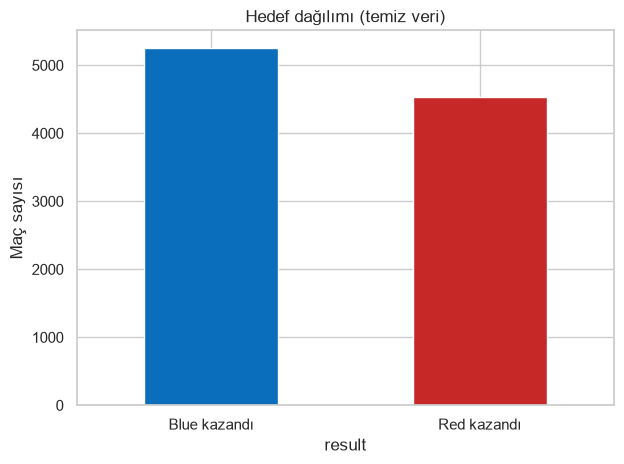

result
1    0.5369
0    0.4631
Name: proportion, dtype: float64

In [9]:
ax = data.result.map({1: 'Blue kazandı', 0: 'Red kazandı'}).value_counts().plot.bar(color=['#0a6ebd', '#c62828'], rot=0)
ax.set_title('Hedef dağılımı (temiz veri)'); ax.set_ylabel('Maç sayısı'); plt.tight_layout(); plt.savefig(FIG/'target_distribution.png', dpi=120); plt.show()
data.result.value_counts(normalize=True).round(4)

Blue tarafı ~%53.7 kazanıyor: hafif bir dengesizlik var ama sınıf ağırlıklandırması gerektirecek kadar değil. Referans (baseline) olarak "her zaman Blue" tahmini bu oranda doğruluk verir.

## 6. Özelliklerin dağılımı ve aykırı değerler

In [10]:
data[FEATURES].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
golddiffat10,9776.0,134.9,1578.5,-7495.0,-876.0,113.0,1125.0,10446.0
xpdiffat10,9776.0,102.4,1163.9,-6305.0,-620.2,89.0,817.2,6879.0
csdiffat10,9776.0,3.0,29.1,-155.0,-16.0,3.0,22.0,125.0
killsat10,9776.0,2.7,2.2,0.0,1.0,2.0,4.0,24.0
deathsat10,9776.0,2.6,2.1,0.0,1.0,2.0,4.0,16.0


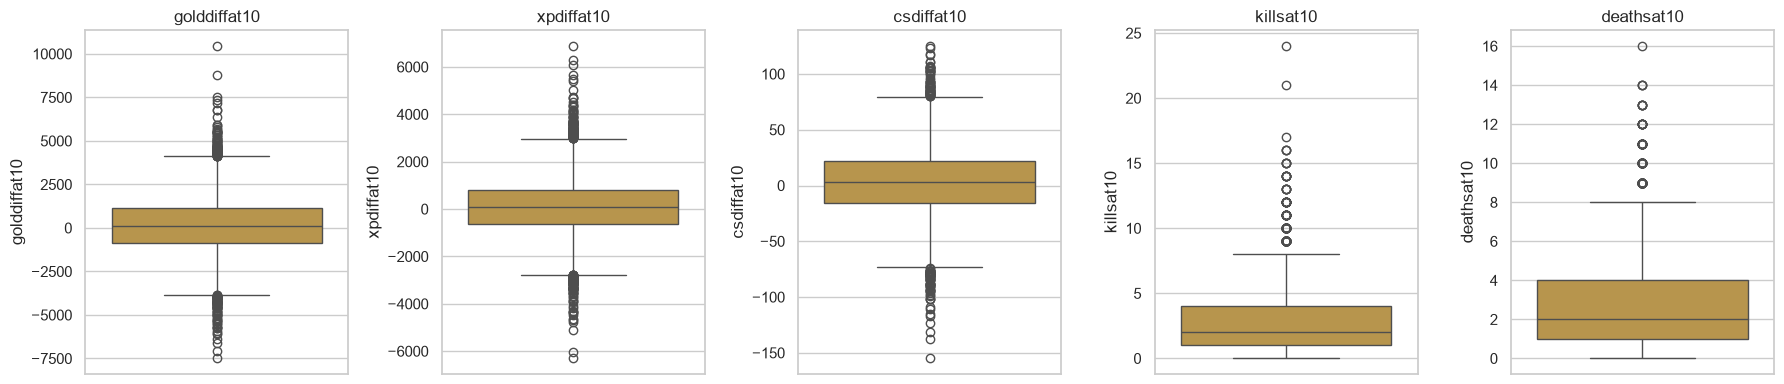

,IQR aykırı sayısı
golddiffat10,177
xpdiffat10,202
csdiffat10,126
killsat10,178
deathsat10,159


In [11]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, f in zip(axes, FEATURES):
    sns.boxplot(y=data[f], ax=ax, color='#c89b3c'); ax.set_title(f)
plt.tight_layout(); plt.savefig(FIG/'boxplots.png', dpi=120); plt.show()
q1, q3 = data[FEATURES].quantile(.25), data[FEATURES].quantile(.75); iqr = q3 - q1
((data[FEATURES] < q1 - 1.5*iqr) | (data[FEATURES] > q3 + 1.5*iqr)).sum().to_frame('IQR aykırı sayısı')

**Karar:** IQR yöntemine göre aykırı görünen değerler (ör. 10. dakikada +10.000 altın, 24 kill) gerçek tek taraflı maçlardır; ölçüm hatası değildir ve tahmin için en bilgilendirici örneklerdendir. Bu yüzden çıkarılmadı. Logistic Regression için `StandardScaler`, ağaç modelleri ise aykırılardan zaten az etkilenir.

## 7. Gold, XP ve CS farklarının galibiyetle ilişkisi

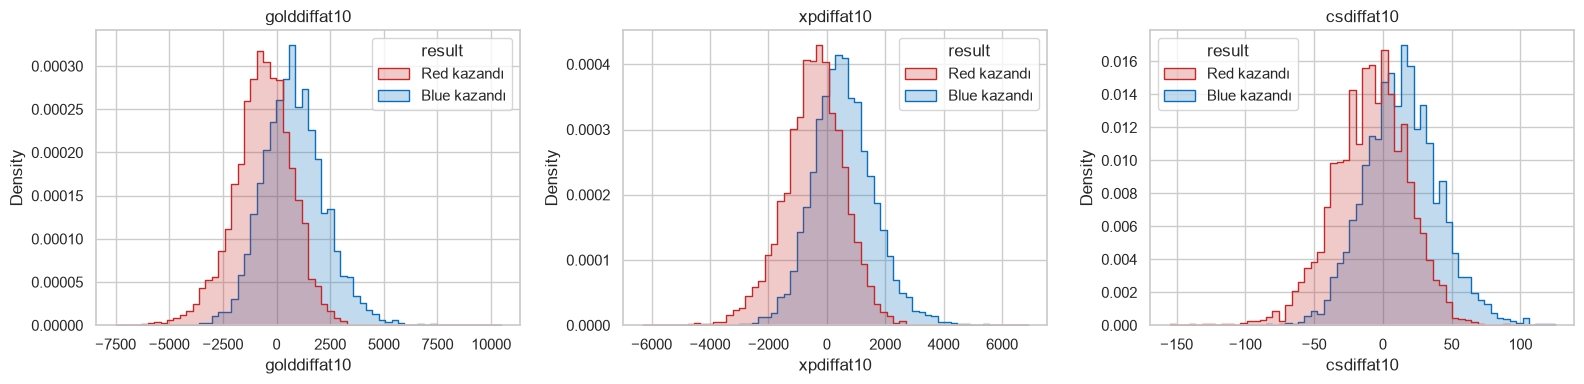

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, f in zip(axes, ['golddiffat10', 'xpdiffat10', 'csdiffat10']):
    sns.histplot(data=data, x=f, hue=data.result.map({1:'Blue kazandı',0:'Red kazandı'}), bins=60, ax=ax, element='step', stat='density', common_norm=False,
                 palette={'Blue kazandı':'#0a6ebd','Red kazandı':'#c62828'})
    ax.set_title(f)
plt.tight_layout(); plt.savefig(FIG/'diff_distributions.png', dpi=120); plt.show()

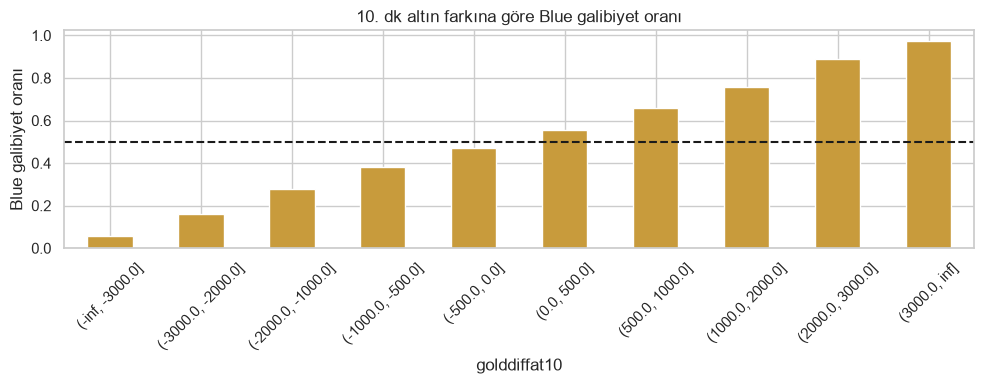

,mean,size
golddiffat10,,
"(-inf, -3000.0]",0.055,255
"(-3000.0, -2000.0]",0.161,497
"(-2000.0, -1000.0]",0.280,1393
"(-1000.0, -500.0]",0.382,1202
"(-500.0, 0.0]",0.469,1228
"(0.0, 500.0]",0.555,1303
"(500.0, 1000.0]",0.661,1220
"(1000.0, 2000.0]",0.760,1616
"(2000.0, 3000.0]",0.887,708


In [13]:
bins = [-np.inf, -3000, -2000, -1000, -500, 0, 500, 1000, 2000, 3000, np.inf]
wr = data.groupby(pd.cut(data.golddiffat10, bins), observed=True).result.agg(['mean', 'size'])
ax = wr['mean'].plot.bar(color='#c89b3c', rot=45, figsize=(10, 4)); ax.axhline(.5, ls='--', c='k')
ax.set_ylabel('Blue galibiyet oranı'); ax.set_title('10. dk altın farkına göre Blue galibiyet oranı')
plt.tight_layout(); plt.savefig(FIG/'winrate_by_golddiff.png', dpi=120); plt.show()
wr.round(3)

Altın farkı arttıkça galibiyet oranı monoton biçimde artıyor: 10. dakikada +3000 altın önde olan Blue takımı maçların büyük çoğunluğunu kazanıyor.

## 8. Korelasyonlar

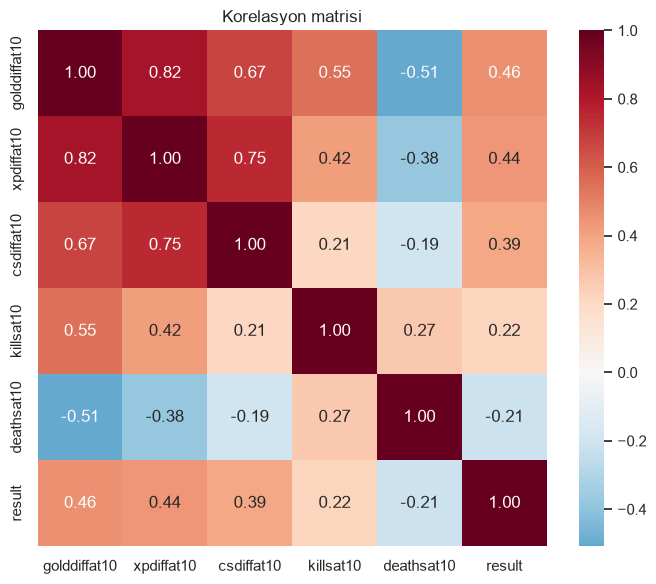

In [14]:
corr = data[FEATURES + ['result']].corr()
plt.figure(figsize=(7, 6)); sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Korelasyon matrisi'); plt.tight_layout(); plt.savefig(FIG/'correlation.png', dpi=120); plt.show()

`golddiffat10`, `xpdiffat10` ve `csdiffat10` birbiriyle güçlü korelasyonlu (çoklu doğrusallık). Bu, ağaç modellerini ve tahmin gücünü bozmaz; ancak Logistic Regression katsayılarını tek tek yorumlarken dikkat edilmelidir.

## 9. Tarih ve patch dağılımı

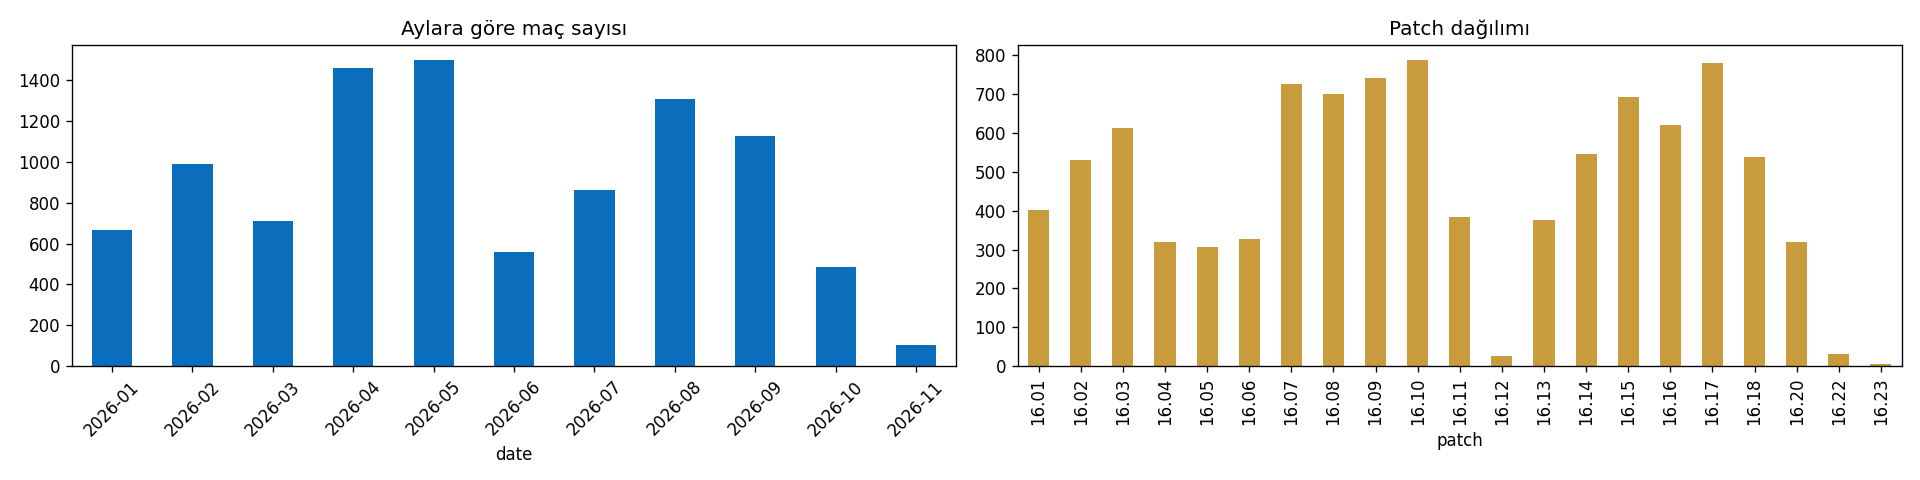

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
data.date.dt.strftime('%Y-%m').value_counts().sort_index().plot.bar(ax=axes[0], color='#0a6ebd', rot=45)
axes[0].set_title('Aylara göre maç sayısı')
data.sort_values('date').groupby('patch', sort=False).size().plot.bar(ax=axes[1], color='#c89b3c'); axes[1].set_title('Patch dağılımı')
plt.tight_layout(); plt.savefig(FIG/'date_patch.png', dpi=120); plt.show()

In [16]:
data.league.value_counts().head(15).to_frame('maç')

,maç
league,
LAS,576
LPL,553
EM,524
LCK,502
LCKC,491
LEC,382
AL,365
LJL,363
PRM,300


Veri 2026 Ocak–Kasım arasını kapsıyor. Meta değiştikçe (patch) ilişkiler değişebileceğinden modelde **kronolojik bölme** kullanıldı: eski %80 maç eğitim, en yeni %20 maç test. Böylece model gerçek kullanımdaki gibi "geleceği" tahmin ediyor.

## 10. Temizleme kararlarının özeti

| Adım | Karar | Gerekçe |
|---|---|---|
| Maç başına satır | Yalnız Blue satırı | Fark sütunları simetrik; aynı maç iki kez girmez |
| Tüm 10. dk değerleri 0 (175 maç) | Çıkarıldı | `goldat10=0` imkânsız → eksik kayıt |
| Eksik değerli sütunlar (ban, split, bo_format…) | Kullanılmadı | Modelle ilgisiz |
| Aykırı değerler | Tutuldu | Gerçek tek taraflı maçlar |
| Maç sonu sütunları (kills, towers, gamelength…) | Kullanılmadı | 10. dakikada bilinmez → veri sızıntısı |
| `game_id`, takım adları | Kullanılmadı | Kimlik bilgisi, genellenebilir değil |
| 15. dk sütunları | Kullanılmadı | Problem 10. dk ile sınırlı |